# 01. Iris 
## 1. Business understanding

The goal of this assignment is to create an FCN neural network model to identify iris plants from 4 features. 

## 2. Data understanding

Lets start with imports and importing the iris dataset from https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import keras
from keras.models import Sequential
from keras.layers import Input, Dense, Flatten
from keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from keras.callbacks import EarlyStopping

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

random_state = 69420
keras.utils.set_random_seed(random_state)

In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"
cols = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]

df = pd.read_csv(url, header=None, names=cols)
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [4]:
df['species'].value_counts()

species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

We have 4 columns `sepal_length`, `sepal_width`, `petal_length`, `petal_width` and target `species` which is in the format of `Iris-[class]`. Classes have even split.

## 3. Data preprocessing

Next up lets clean up the class names, we dont need `Iris-` prefix. Lets also one-hot encode class names

In [5]:
df['species'] = df['species'].str.replace('Iris-', '', regex=False)

df = df.sample(frac=1, random_state=random_state).reset_index(drop=True)
X = df.drop(columns=['species'])
y = df['species'].astype('category').cat.codes
y = to_categorical(y, 3)

## 4. Modeling

Lets try different neuron counts, `4`, `8`, `16`, `128`

In [6]:
early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

for units in [4, 8, 16, 128]:
    keras.utils.set_random_seed(random_state)
    m = Sequential([Input(shape=(4,)),
                    Dense(units, activation='relu'),
                    Dense(3, activation='softmax')])
    m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    h = m.fit(X, y, epochs=200, batch_size=16, validation_split=0.2, verbose=0, callbacks=early_stop)
    print(f"{units:>4} units: train acc {h.history['accuracy'][-1]:.3f}, "
          f"val acc {h.history['val_accuracy'][-1]:.3f}")

   4 units: train acc 0.975, val acc 1.000
   8 units: train acc 0.967, val acc 0.967
  16 units: train acc 0.975, val acc 0.967
 128 units: train acc 0.983, val acc 0.967


After `16` neurons `val acc` doesnt rise anymore at `128`  which is notably larger model so lets pick `16` for our model

In [7]:
model = Sequential([
    Input(shape=(4,)),
    Dense(16, activation='relu'),
    Dense(3, activation='softmax')
])

Lets compile the model with `adam` optimizer and `accuracy` as interesting metric

In [8]:
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [9]:
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 131 (524.00 B)

 Trainable params: 131 (524.00 B)

 Non-trainable params: 0 (0.00 B)

Lets make sure that overfitting doesnt happen with `EarlyStopping` which restores best weights if `val_loss` starts rising

In [10]:
early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

history = model.fit(X, y, epochs=200, batch_size=16, validation_split=0.2, verbose=0, callbacks=early_stop)
print(f"stopped after {len(history.history['loss'])} epochs")

stopped after 200 epochs


All 200 epochs ran so no overfitting

## 5. Evaluation

Validation accuracy is `96.7%` and validation loss `13.1%`. Best training accuracy is `98.3%`

In [11]:
print(f"Final validation accuracy: {history.history['val_accuracy'][-1]:.3}")
print(f"Final validation loss: {history.history['val_loss'][-1]:.3}")
best = int(np.argmin(history.history['val_loss']))
print(f"Best training accuracy: {history.history['accuracy'][best]:.3}")

Final validation accuracy: 0.967
Final validation loss: 0.131
Best training accuracy: 0.983


In [12]:
classes = ['setosa', 'versicolor', 'virginica']

n_val = int(0.2 * len(X))
X_val, y_val = X[-n_val:], y[-n_val:]
probs = model.predict(X_val, verbose=0)
true = y_val.argmax(axis=1)

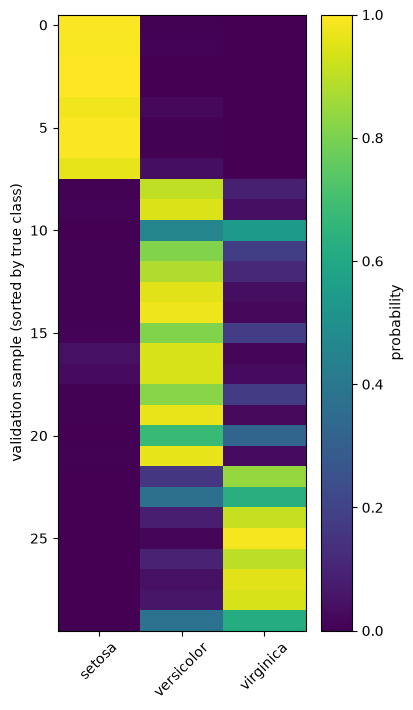

In [13]:
order = np.argsort(true, kind='stable')
fig, ax = plt.subplots(figsize=(4, 8))
im = ax.imshow(probs[order], aspect='auto', cmap='viridis', vmin=0, vmax=1)
ax.set_xticks(range(3), classes, rotation=45)
ax.set_ylabel('validation sample (sorted by true class)')
plt.colorbar(im, label='probability')
plt.show()

Heatmap shows us that `setosa` gets identified perfectly, which is expected. `versicolor` and `virginica` gets more mixed up but overall they are also identified fairly accurately.

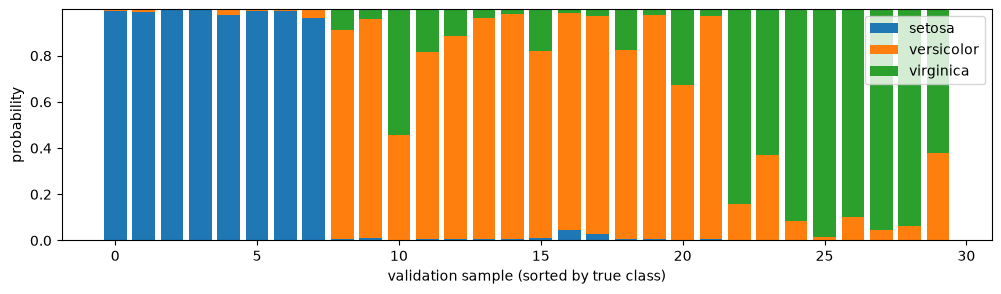

In [14]:
fig, ax = plt.subplots(figsize=(12, 3))
bottom = np.zeros(len(probs))
for k, name in enumerate(classes):
    ax.bar(range(len(probs)), probs[order][:, k], bottom=bottom, label=name)
    bottom += probs[order][:, k]
ax.set_xlabel('validation sample (sorted by true class)')
ax.set_ylabel('probability')
ax.legend(loc='upper right')
plt.show()

The bar graph above shows us better the confidence of each prediction. `10`th sample gets misidentified as `virginica`.  
The evaluation portion might not be accurate since the model knows the data used for evaluation.

## 6. Deployment

The model could be deployed to identify iris plants. Possibly in the form of an API.